# 02 · Preprocessing: from event logs to model-ready matrices

**Objective.** Turn the OPC UA event logs of one subsystem (coolant first) into model-ready matrices at **Δ = 0.5 s and Δ = 1 s**, measure what each interval costs, and produce the inputs later stages need: which variables each run records, which pairs are recorded together, and explicit recording splits.

**Inputs.** Raw events (read with the tested `preprocessing.py` functions), fault metadata (`data.py`), and the subsystem *variable set* from the expert graph. No expert edges are used, except in figure 8, which is flagged as context only.

**Assumptions.**
- An OPC UA value holds until the next published change, so states are reconstructed by zero-order hold (forward fill).
- The t = 0 rows are the recorder's initial snapshot. Before a variable's first event its state is unknown and is never backfilled.
- A variable without any event in a recording is unknown for the whole recording. It is masked, never filled with a *healthy* value.
- Each recording has its own grid from t = 0; recordings are never joined or aligned.
- Recording numbers of normal recordings grow with time (used for the ordered split; not verified).

**Leakage rules.** No `causes.json` timestamps or description fields enter the matrices. The experiment id is only used to group runs into folds. Which variables a fault run records reveals its scenario, so later stages must not use that pattern as evidence.

**Outputs.** Figures `results/figures/02_*`, tables `results/tables/02_*`, model-ready files `data/processed/<subsystem>_dt0.5.npz|json` and `<subsystem>_dt1.npz|json`.

In [1]:
from dataclasses import asdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.ticker import PercentFormatter

from causal_rca import data
from causal_rca import evaluation as ev
from causal_rca import preprocessing as pp

ev.set_plot_style()
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 180)

# subsystem studied here; change to 'hydraulics' or 'probe' to re-run
SUBSYSTEM = 'coolant'
# candidate sampling intervals from the eda
INTERVALS = [0.5, 1.0]
DT_COLORS = {0.5: ev.COLORS[0], 1.0: ev.COLORS[1]}

In [2]:
# metadata, subsystem variable set and the recordings used here
infos = pp.discover_recordings(data.RAW_DIR)
recordings = pd.DataFrame([asdict(r) for r in infos])
experiments = data.load_experiments()
runs = data.load_fault_runs()
graph = data.load_expert_graph(subsystem=SUBSYSTEM)
# only the variable set of the subsystem is used, not its edges
NODES = sorted(graph.nodes)

normal_ids = recordings.loc[recordings.source == 'real_op', 'recording_id'].tolist()
fault_ids = runs.loc[runs.subsystem == SUBSYSTEM, 'recording_id'].tolist()
EXAMPLE_RUN = fault_ids[0]

# parse the normal recordings and this subsystem's fault runs
keep = set(normal_ids + fault_ids)
events = pp.parse_values(pp.load_all_events([r for r in infos if r.recording_id in keep], data.RAW_DIR))
events, duplicate_log = pp.resolve_duplicates(events)
events = pp.mark_changes(events)
types = pp.node_types(events)

# discrete view when every subsystem variable is discrete, mixed otherwise
VIEW_KIND = 'discrete' if all(types[n] in pp.DISCRETE_TYPES for n in NODES) else 'mixed'
print(f'{SUBSYSTEM}: {len(NODES)} variables, {len(normal_ids)} normal recordings, {len(fault_ids)} fault runs')
print(f'{len(events):,} events, {len(duplicate_log)} duplicate events, view kind: {VIEW_KIND}, example run: {EXAMPLE_RUN}')

coolant: 15 variables, 170 normal recordings, 25 fault runs
431,749 events, 0 duplicate events, view kind: discrete, example run: coolant_exp_22_run_1


## A. Raw events → parsed values

Every raw field is kept as an unmodified string (`time_s_raw`, `raw_value`). Values are parsed by their declared type: Binary/Alarm strictly to 0/1, Continuous/Counter to floats, Categorical kept as strings.

In [3]:
# raw strings next to parsed values for the example run
example = events[(events.recording_id == EXAMPLE_RUN) & events.node.isin(NODES)]
example[['time_s_raw', 'node', 'type', 'raw_value', 'value_num', 'is_initial', 'is_change']].head(25)

,time_s_raw,node,type,raw_value,value_num,is_initial,is_change
6,0.0,HP_A_700304,Alarm,False,0.0,True,False
7,0.0,HP_Pump_Ok,Binary,True,1.0,True,False
8,0.0,HP_Pump_isOff,Binary,True,1.0,True,False
9,0.0,LP_Pump_On,Binary,False,0.0,True,False
10,0.0,LT_A_700317,Alarm,False,0.0,True,False
11,0.0,LT_Level_Ok,Binary,True,1.0,True,False
12,0.0,LT_Pump_Ok,Binary,True,1.0,True,False
366,78.705,LP_Pump_On,Binary,True,1.0,False,True
369,79.319,HP_Pump_isOff,Binary,False,0.0,False,True
384,80.235,LP_Pump_On,Binary,False,0.0,False,True


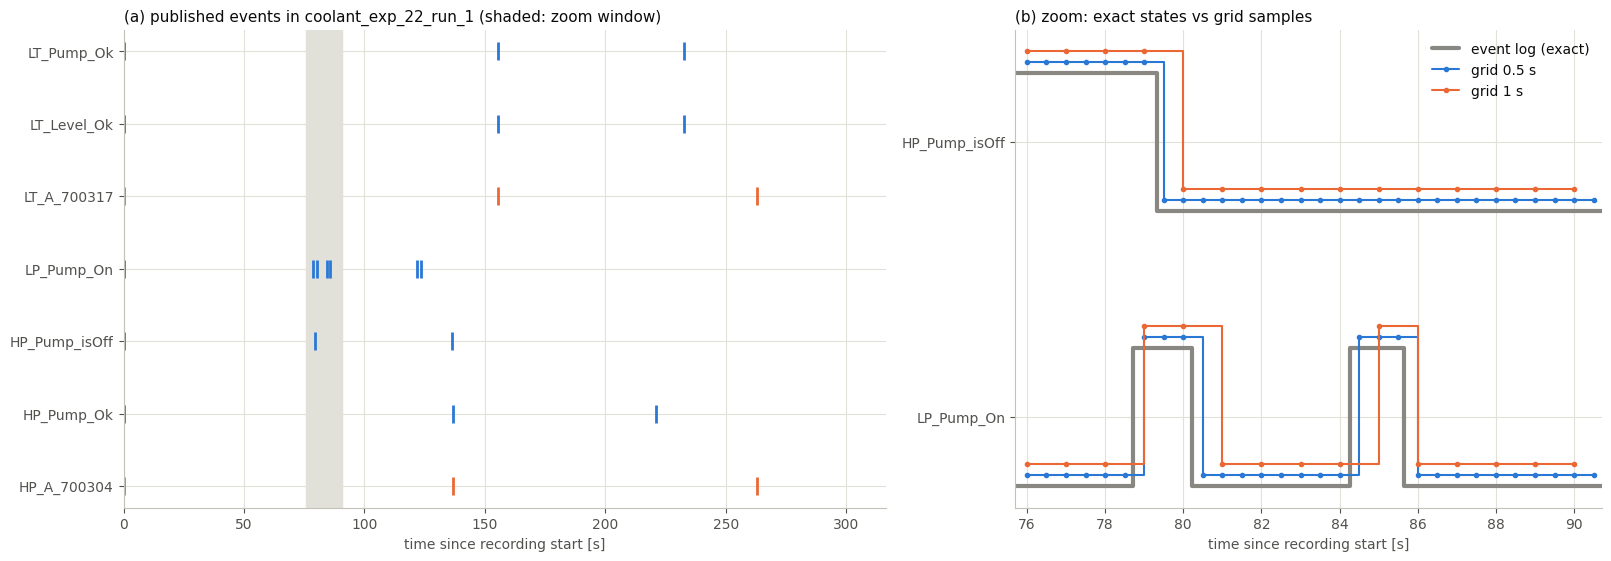

In [4]:
# figure 1: published events and reconstructed states of the example run
recorded = [n for n in NODES if n in set(example.node)]
run_events = events[events.recording_id == EXAMPLE_RUN]
example_states = {dt: pp.reconstruct_states(run_events, dt, nodes=recorded) for dt in INTERVALS}
t_end = run_events.time_s.max()

# zoom on the two variables that change most often in this run
change_counts = example[example.is_change].node.value_counts()
zoom_nodes = change_counts.index[:2].tolist()
t_first = example[(example.node == zoom_nodes[0]) & example.is_change].time_s.min()
window = (t_first - 3, t_first + 12)

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1.3, 1]}, layout='constrained')

# panel a: one tick per published event
for i, node in enumerate(recorded):
    times = example.loc[example.node == node, 'time_s']
    ax_a.scatter(times, np.full(len(times), i), marker='|', s=150, color=ev.TYPE_COLORS[types[node]])
ax_a.set_yticks(range(len(recorded)), recorded)
ax_a.axvspan(*window, color=ev.INK['grid'], zorder=0)
ax_a.set_xlim(0, t_end)
ax_a.set_xlabel('time since recording start [s]')
ax_a.set_title(f'(a) published events in {EXAMPLE_RUN} (shaded: zoom window)')

# panel b: exact state from the event log vs samples on each grid
for i, node in enumerate(zoom_nodes):
    e = example[example.node == node].sort_values('time_s')
    lo, hi = e.value_num.min(), e.value_num.max()
    span = hi - lo if hi > lo else 1.0
    t = np.append(e.time_s, t_end)
    v = (np.append(e.value_num, e.value_num.iloc[-1]) - lo) / span
    base = 2 * i
    ax_b.step(t, base + v, where='post', color=ev.INK['muted'], linewidth=3,
              label='event log (exact)' if i == 0 else None)
    for k, dt in enumerate(INTERVALS):
        s = example_states[dt]
        s = s[(s.t_s >= window[0]) & (s.t_s <= window[1])]
        sampled = (s[node].astype(float).to_numpy() - lo) / span
        # small offset so the grids do not hide each other
        ax_b.step(s.t_s, base + sampled + 0.08 * (k + 1), where='post', color=DT_COLORS[dt], linewidth=1.5,
                  marker='o', markersize=3, label=f'grid {dt:g} s' if i == 0 else None)
ax_b.set_xlim(*window)
ax_b.set_yticks([2 * i + 0.5 for i in range(len(zoom_nodes))], zoom_nodes)
ax_b.set_xlabel('time since recording start [s]')
ax_b.set_title('(b) zoom: exact states vs grid samples')
ax_b.legend(loc='upper right')
ev.save_figure(fig, f'02_{SUBSYSTEM}_reconstruction_example')
plt.show()

**What to look for.** In panel (b) a grid shows a change at the first grid point at or after the event, so a change appears up to Δ late. Pulses shorter than Δ can disappear. Note how many events in panel (a) line up at the same time: these are the batched publications seen in the EDA.

## B. Variable type handling

In [5]:
# declared type, graph role and state dtype of each subsystem variable
variables = pd.DataFrame({
    'variable': NODES,
    'declared_type': [types[n] for n in NODES],
    'graph_kind': [graph.nodes[n]['kind'] for n in NODES],
    'io': [graph.nodes[n]['io'] for n in NODES],
    'state_dtype': [pp.state_dtype(types[n]) for n in NODES],
})
variables

,variable,declared_type,graph_kind,io,state_dtype
0,CLF_A_700307,Alarm,Alarm,None,Int8
1,CLF_Filter_Ok,Binary,Variable,input,Int8
2,CLT_A_700310,Alarm,Alarm,None,Int8
3,CLT_Level_lt_Min,Binary,Variable,input,Int8
4,F_A_700313,Alarm,Alarm,None,Int8
5,F_Filter_Ok,Binary,Variable,input,Int8
6,HP_A_700304,Alarm,Alarm,None,Int8
7,HP_Pump_Ok,Binary,Variable,input,Int8
8,HP_Pump_isOff,Binary,Variable,input,Int8
9,LP_A_700301,Alarm,Alarm,None,Int8


In [6]:
# guard: numeric-looking categoricals stay strings (checked on Prog_LineNo in normal data)
line_no = events[events.node == 'Prog_LineNo']
print('value_cat dtype:', line_no.value_cat.dtype, '| value_num all missing:', line_no.value_num.isna().all())
line_no[['recording_id', 'time_s', 'raw_value', 'value_num', 'value_cat']].head()

value_cat dtype: string | value_num all missing: True


,recording_id,time_s,raw_value,value_num,value_cat
29,coolant_exp_22_run_1,0.000,0,NaN,0
80,coolant_exp_22_run_1,35.497,202,NaN,202
88,coolant_exp_22_run_1,38.599,132,NaN,132
93,coolant_exp_22_run_1,39.557,45,NaN,45
100,coolant_exp_22_run_1,40.558,106,NaN,106


## C. Variable coverage: which runs record which variables

Fault runs only record the variables of their scenario. A variable without events in a run is unknown there. Pairs of variables that are never recorded together cannot be tested by any conditional independence test.

In [7]:
# true where a recording has at least one event of the variable
coverage = data.variable_coverage(events, NODES)
fault_coverage = coverage.loc[fault_ids]
normal_share = coverage.loc[normal_ids].mean()

coverage_table = fault_coverage.astype(int).T
coverage_table.insert(0, 'normal_share', normal_share)
ev.save_table(coverage_table.reset_index(names='variable'), f'02_{SUBSYSTEM}_coverage')
fault_coverage.sum().rename('fault runs recording the variable').to_frame().T

node,CLF_A_700307,CLF_Filter_Ok,CLT_A_700310,CLT_Level_lt_Min,F_A_700313,F_Filter_Ok,HP_A_700304,HP_Pump_Ok,HP_Pump_isOff,LP_A_700301,LP_Pump_Ok,LP_Pump_On,LT_A_700317,LT_Level_Ok,LT_Pump_Ok
fault runs recording the variable,12,12,7,7,6,6,13,13,25,12,12,25,6,6,12


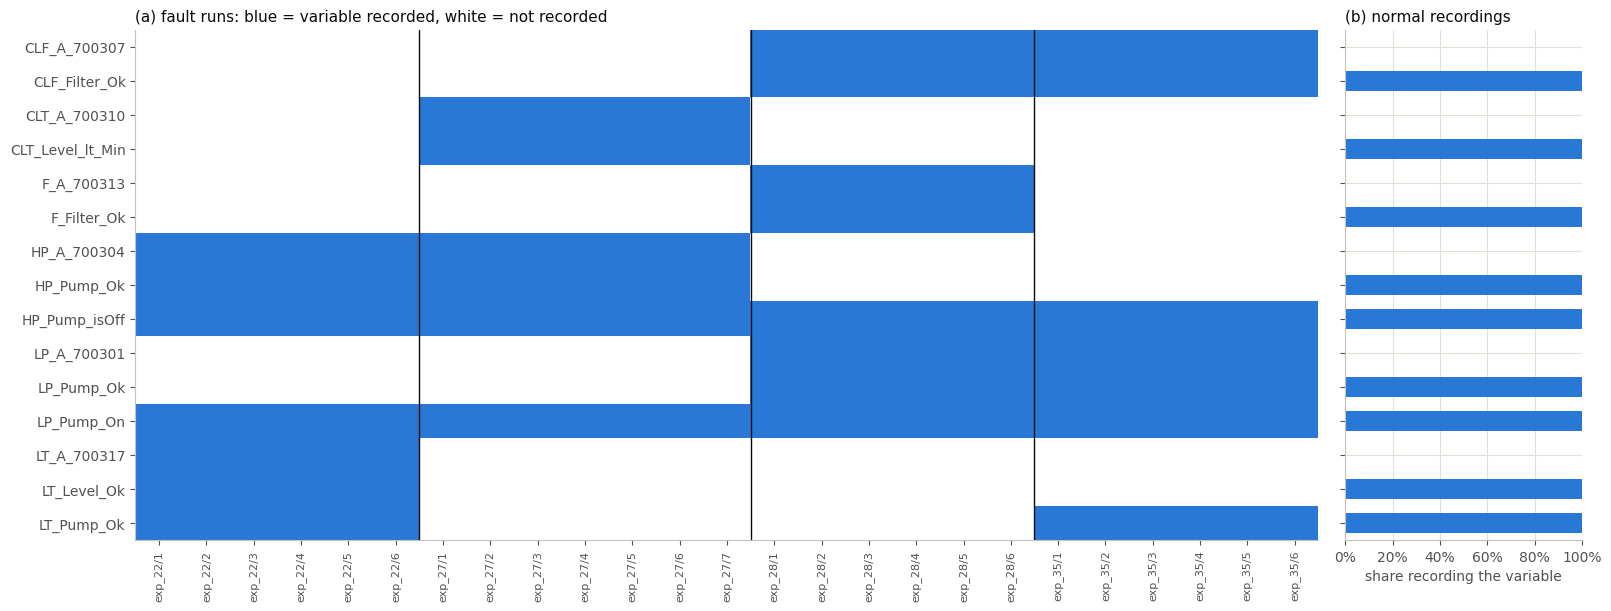

In [8]:
# figure 2: recorded variables per fault run, and in normal operation
run_labels = [rid.removeprefix(f'{SUBSYSTEM}_').replace('_run_', '/') for rid in fault_ids]
scenario_of = runs.set_index('recording_id').loc[fault_ids, 'experiment_id'].tolist()

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(16, 6), sharey=True, gridspec_kw={'width_ratios': [5, 1]}, layout='constrained')
ax_a.imshow(fault_coverage.T.astype(float).to_numpy(), cmap=ListedColormap([ev.INK['surface'], ev.COLORS[0]]),
            aspect='auto', vmin=0, vmax=1)
ax_a.set_xticks(range(len(fault_ids)), run_labels, rotation=90, fontsize=8)
ax_a.set_yticks(range(len(NODES)), NODES)
ax_a.grid(False)
# vertical lines between scenarios
for k in range(1, len(scenario_of)):
    if scenario_of[k] != scenario_of[k - 1]:
        ax_a.axvline(k - 0.5, color=ev.INK['primary'], linewidth=1)
ax_a.set_title('(a) fault runs: blue = variable recorded, white = not recorded')

ax_b.barh(range(len(NODES)), normal_share.loc[NODES], color=ev.COLORS[0], height=0.6)
ax_b.xaxis.set_major_formatter(PercentFormatter(1.0))
ax_b.set_xlim(0, 1)
ax_b.set_xlabel('share recording the variable')
ax_b.set_title('(b) normal recordings')
ev.save_figure(fig, f'02_{SUBSYSTEM}_variable_coverage')
plt.show()

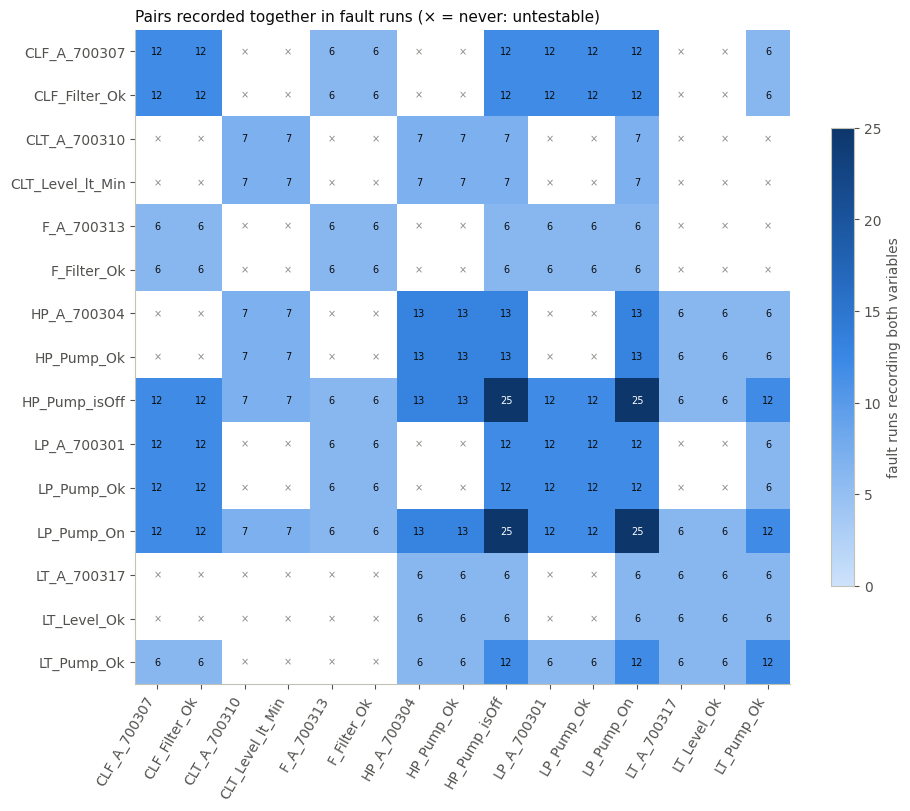

44 of 105 variable pairs are never recorded together in fault runs


PosixPath('/Users/shwetabambal/Desktop/thesis/causalAI-failure-prevention/results/tables/02_coolant_co_observation.csv')

In [9]:
# figure 3: number of fault runs in which both variables are recorded
co = data.co_observation(fault_coverage)
counts = co.to_numpy()

fig, ax = plt.subplots(figsize=(9.5, 8), layout='constrained')
cmap = ev.sequential_cmap()
cmap.set_bad(ev.INK['surface'])
image = ax.imshow(np.ma.masked_equal(counts, 0), cmap=cmap, vmin=0, vmax=len(fault_ids))
for (i, j), c in np.ndenumerate(counts):
    color = ev.INK['muted'] if c == 0 else (ev.INK['surface'] if c > 0.55 * len(fault_ids) else ev.INK['primary'])
    ax.text(j, i, '×' if c == 0 else str(c), ha='center', va='center', fontsize=7, color=color)
ax.set_xticks(range(len(NODES)), NODES, rotation=60, ha='right')
ax.set_yticks(range(len(NODES)), NODES)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.7, label='fault runs recording both variables')
ax.set_title('Pairs recorded together in fault runs (× = never: untestable)')
ev.save_figure(fig, f'02_{SUBSYSTEM}_co_observation')
plt.show()

untestable = [(a, b) for i, a in enumerate(NODES) for b in NODES[i + 1:] if co.loc[a, b] == 0]
print(f'{len(untestable)} of {len(NODES) * (len(NODES) - 1) // 2} variable pairs are never recorded together in fault runs')
ev.save_table(co.reset_index(names='variable'), f'02_{SUBSYSTEM}_co_observation')

**What to look for.** How many pairs are untestable, and whether any expert-graph edges fall among them. Stage 2 must report such pairs as *untestable*, never as *independent*.

## D. State reconstruction at 0.5 s and 1 s

Zero-order hold per recording, NA before a variable's first event, no backfill, no filling across recordings. Every state cell is then re-derived from the events by a separate method (`verify_states`).

In [10]:
# reconstruct all selected recordings at both intervals and verify them against the events
states = {}
checks = []
for dt in INTERVALS:
    # the grid of a recording uses all its events; the columns are the subsystem variables
    states[dt] = pp.reconstruct_states(events, dt, nodes=NODES)
    checks.append(pp.verify_states(events, states[dt], dt).to_dict())
pd.DataFrame(checks)[['interval_s', 'n_recordings', 'n_cells_checked', 'n_mismatches', 'n_grid_errors', 'passed']]

,interval_s,n_recordings,n_cells_checked,n_mismatches,n_grid_errors,passed
0,0.5,195,3178965,0,0,True
1,1.0,195,1591560,0,0,True


## E. Comparing 0.5 s and 1 s

Four criteria: value changes kept per variable, changes hidden inside one grid step, steps where the grid cannot order changes, and the cost in rows and look-back steps.

In [11]:
# per recording, variable and grid step: changes inside the step and whether the grid shows one
bins = pd.concat(
    [pp.transition_bins(events[events.node.isin(NODES)], dt).assign(interval_s=dt) for dt in INTERVALS],
    ignore_index=True,
)
comparison = (
    bins.groupby(['interval_s', 'source', 'node'])
    .agg(true_changes=('n_changes', 'sum'), visible=('visible', 'sum'), masked_steps=('masked', 'sum'))
    .reset_index()
)
comparison['retention'] = comparison.visible / comparison.true_changes.where(comparison.true_changes > 0)
ev.save_table(comparison, f'02_{SUBSYSTEM}_sampling_comparison')
comparison.pivot_table(index='node', columns=['source', 'interval_s'], values='retention').round(3)

source           dig_twin      real_op       
interval_s            0.5  1.0     0.5    1.0
node                                         
CLF_A_700307          1.0  1.0     NaN    NaN
CLF_Filter_Ok         1.0  1.0     NaN    NaN
CLT_A_700310          1.0  1.0     NaN    NaN
CLT_Level_lt_Min      1.0  1.0     NaN    NaN
F_A_700313            1.0  1.0     NaN    NaN
F_Filter_Ok           1.0  1.0     NaN    NaN
HP_A_700304           1.0  1.0     NaN    NaN
HP_Pump_Ok            1.0  1.0     NaN    NaN
HP_Pump_isOff         1.0  1.0     1.0  1.000
LP_A_700301           1.0  1.0     NaN    NaN
LP_Pump_Ok            1.0  1.0     NaN    NaN
LP_Pump_On            1.0  1.0     1.0  0.997
LT_A_700317           1.0  1.0     NaN    NaN
LT_Level_Ok           1.0  1.0     1.0  1.000
LT_Pump_Ok            1.0  1.0     1.0  1.000

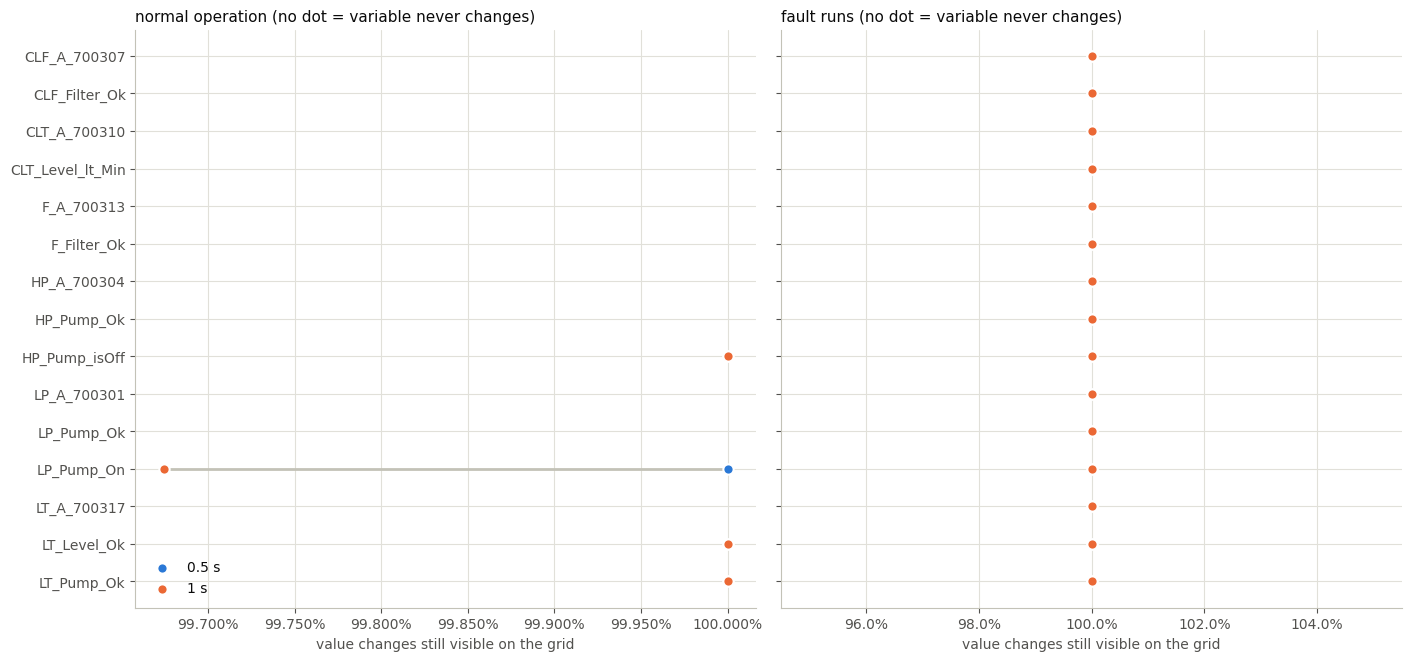

In [12]:
# figure 4: share of value changes still visible per variable, 0.5 s vs 1 s
y = np.arange(len(NODES))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True, layout='constrained')
for ax, source in zip(axes, ['real_op', 'dig_twin']):
    table = comparison[comparison.source == source].pivot(index='node', columns='interval_s', values='retention').reindex(NODES)
    table = table.reindex(columns=INTERVALS)
    ax.hlines(y, table[INTERVALS[0]], table[INTERVALS[1]], color=ev.INK['axis'], linewidth=2, zorder=1)
    for dt in INTERVALS:
        ax.scatter(table[dt], y, s=55, color=DT_COLORS[dt], edgecolor=ev.INK['surface'], linewidth=1.5,
                   zorder=3, label=f'{dt:g} s')
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel('value changes still visible on the grid')
    ax.set_title(f'{ev.SOURCE_LABELS[source]} (no dot = variable never changes)')
axes[0].set_yticks(y, NODES)
# shared y axis: invert once
axes[0].invert_yaxis()
axes[0].legend(loc='lower left')
ev.save_figure(fig, f'02_{SUBSYSTEM}_retention_per_variable')
plt.show()

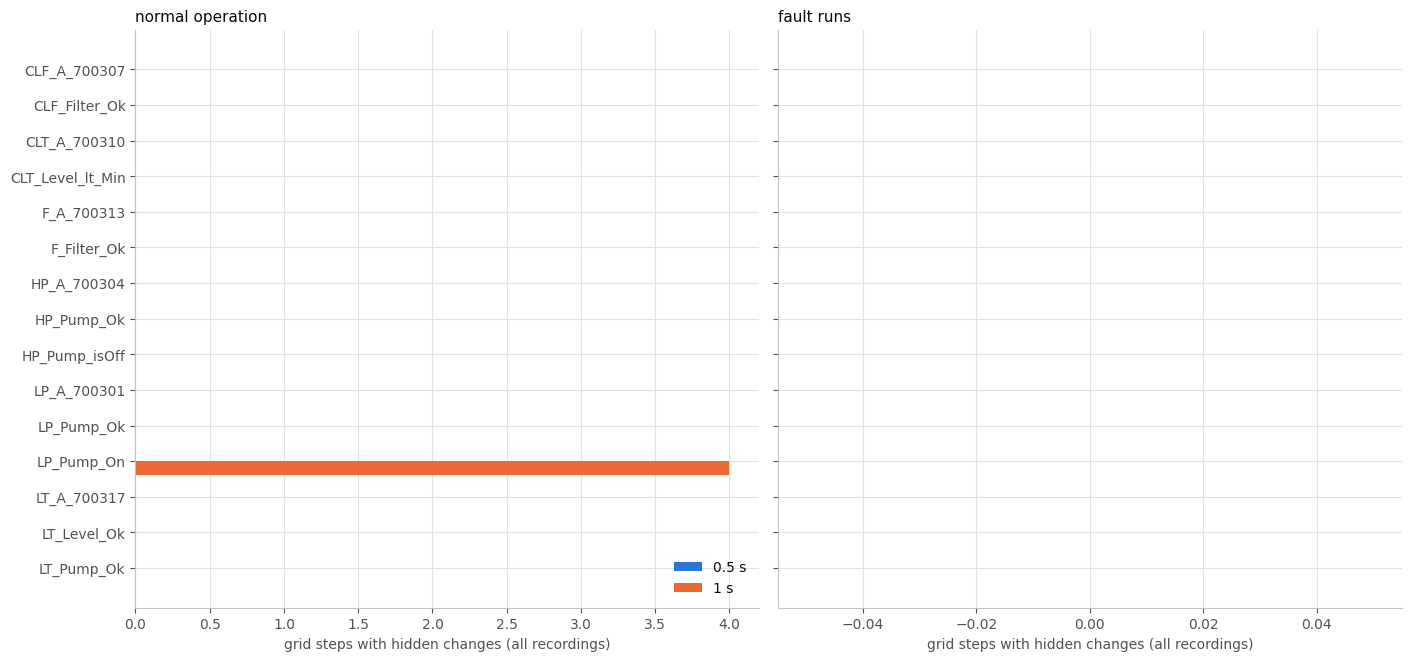

In [13]:
# figure 5: grid steps that hide changes (for example a pulse that starts and ends inside one step)
height = 0.38
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True, layout='constrained')
for ax, source in zip(axes, ['real_op', 'dig_twin']):
    table = comparison[comparison.source == source].pivot(index='node', columns='interval_s', values='masked_steps')
    table = table.reindex(index=NODES, columns=INTERVALS).fillna(0)
    for k, dt in enumerate(INTERVALS):
        ax.barh(y + (k - 0.5) * height, table[dt], height=height, color=DT_COLORS[dt], label=f'{dt:g} s')
    ax.set_xlabel('grid steps with hidden changes (all recordings)')
    ax.set_title(ev.SOURCE_LABELS[source])
axes[0].set_yticks(y, NODES)
axes[0].invert_yaxis()
axes[0].legend(loc='lower right')
ev.save_figure(fig, f'02_{SUBSYSTEM}_hidden_changes')
plt.show()

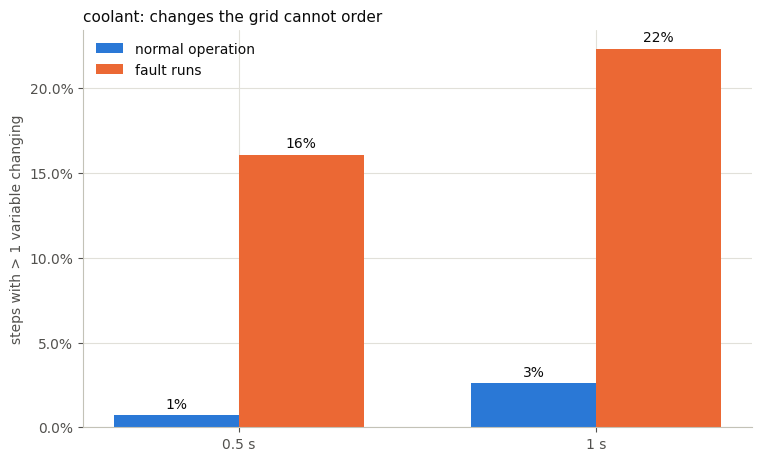

In [14]:
# figure 6: grid steps in which more than one subsystem variable changes
visible = bins[bins.visible]
per_step = visible.groupby(['interval_s', 'source', 'recording_id', 'step']).node.nunique().rename('n_changing').reset_index()
simultaneous = per_step.groupby(['interval_s', 'source']).n_changing.apply(lambda n: (n > 1).mean()).unstack('source')
simultaneous = simultaneous.reindex(index=INTERVALS, columns=['real_op', 'dig_twin'])

fig, ax = plt.subplots(figsize=(7.5, 4.5), layout='constrained')
width = 0.35
for k, source in enumerate(['real_op', 'dig_twin']):
    bars = ax.bar(np.arange(len(INTERVALS)) + (k - 0.5) * width, simultaneous[source], width=width,
                  color=ev.SOURCE_COLORS[source], label=ev.SOURCE_LABELS[source])
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in simultaneous[source]], padding=3)
ax.set_xticks(range(len(INTERVALS)), [f'{dt:g} s' for dt in INTERVALS])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_ylabel('steps with > 1 variable changing')
ax.set_title(f'{SUBSYSTEM}: changes the grid cannot order')
ax.legend()
ev.save_figure(fig, f'02_{SUBSYSTEM}_simultaneous_changes')
plt.show()

In [15]:
# in the example run: grid steps where several subsystem variables change together
for dt in INTERVALS:
    steps = visible[(visible.interval_s == dt) & (visible.recording_id == EXAMPLE_RUN)]
    together = steps.groupby('step').node.apply(sorted)
    together = together[together.str.len() > 1]
    print(f'{dt:g} s grid:')
    for step, changed in together.items():
        print(f'  t = {step * dt:7.1f} s  {changed}')

0.5 s grid:
  t =   137.0 s  ['HP_A_700304', 'HP_Pump_Ok']
  t =   155.5 s  ['LT_Level_Ok', 'LT_Pump_Ok']
  t =   233.0 s  ['LT_Level_Ok', 'LT_Pump_Ok']
  t =   263.0 s  ['HP_A_700304', 'LT_A_700317']
1 s grid:
  t =   137.0 s  ['HP_A_700304', 'HP_Pump_Ok', 'HP_Pump_isOff']
  t =   156.0 s  ['LT_A_700317', 'LT_Level_Ok', 'LT_Pump_Ok']
  t =   233.0 s  ['LT_Level_Ok', 'LT_Pump_Ok']
  t =   263.0 s  ['HP_A_700304', 'LT_A_700317']


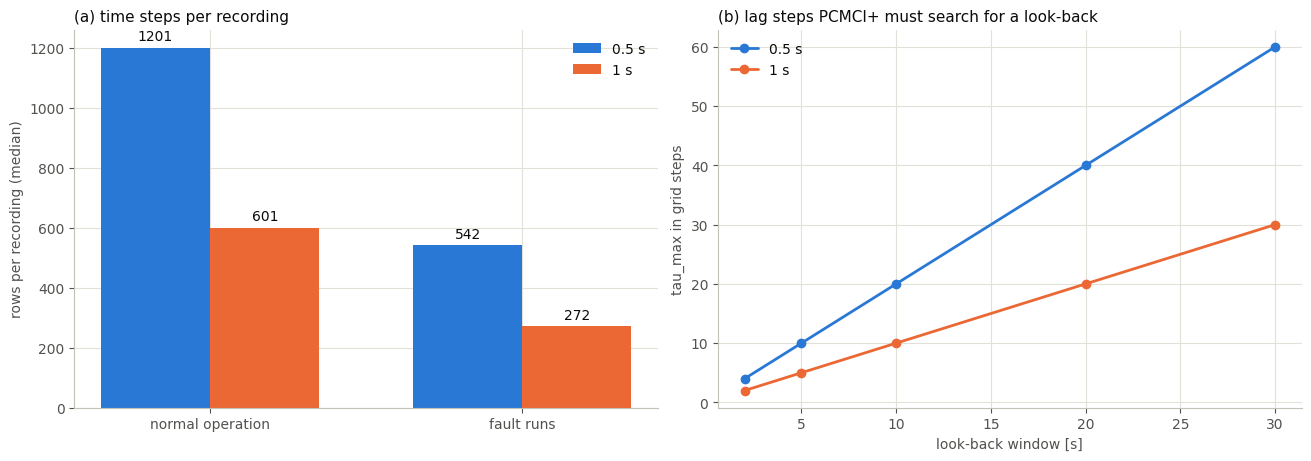

,0.5 s,1 s
total rows,211931,106104
fault-run rows,13821,6931


In [16]:
# figure 7: data size and look-back in steps for each interval
rows = {dt: states[dt].groupby('recording_id').size() for dt in INTERVALS}
source_of = recordings.set_index('recording_id').source
lookback_s = np.array([2, 5, 10, 20, 30])

fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')
width = 0.35
for k, dt in enumerate(INTERVALS):
    by_source = rows[dt].groupby(source_of.reindex(rows[dt].index)).median().reindex(['real_op', 'dig_twin'])
    bars = ax_a.bar(np.arange(2) + (k - 0.5) * width, by_source, width=width, color=DT_COLORS[dt], label=f'{dt:g} s')
    ax_a.bar_label(bars, fmt='%.0f', padding=3)
    ax_b.plot(lookback_s, lookback_s / dt, marker='o', color=DT_COLORS[dt], label=f'{dt:g} s')
ax_a.set_xticks(range(2), [ev.SOURCE_LABELS[s] for s in ['real_op', 'dig_twin']])
ax_a.set_ylabel('rows per recording (median)')
ax_a.set_title('(a) time steps per recording')
ax_a.legend()
ax_b.set_xlabel('look-back window [s]')
ax_b.set_ylabel('tau_max in grid steps')
ax_b.set_title('(b) lag steps PCMCI+ must search for a look-back')
ax_b.legend()
ev.save_figure(fig, f'02_{SUBSYSTEM}_interval_cost')
plt.show()

pd.DataFrame({f'{dt:g} s': {'total rows': int(rows[dt].sum()), 'fault-run rows': int(rows[dt].loc[fault_ids].sum())}
              for dt in INTERVALS})

### Expert-edge onset delays (context only)

> ⚠️ This figure uses the **expert graph edges**. It shows how far apart the onsets of expert cause and effect are in the fault runs. It must **not** be used to tune Stage 2 (e.g. to pick `tau_max`), because Stage 3 evaluates the discovered graph against this same expert graph. Using it for tuning would bias that evaluation.

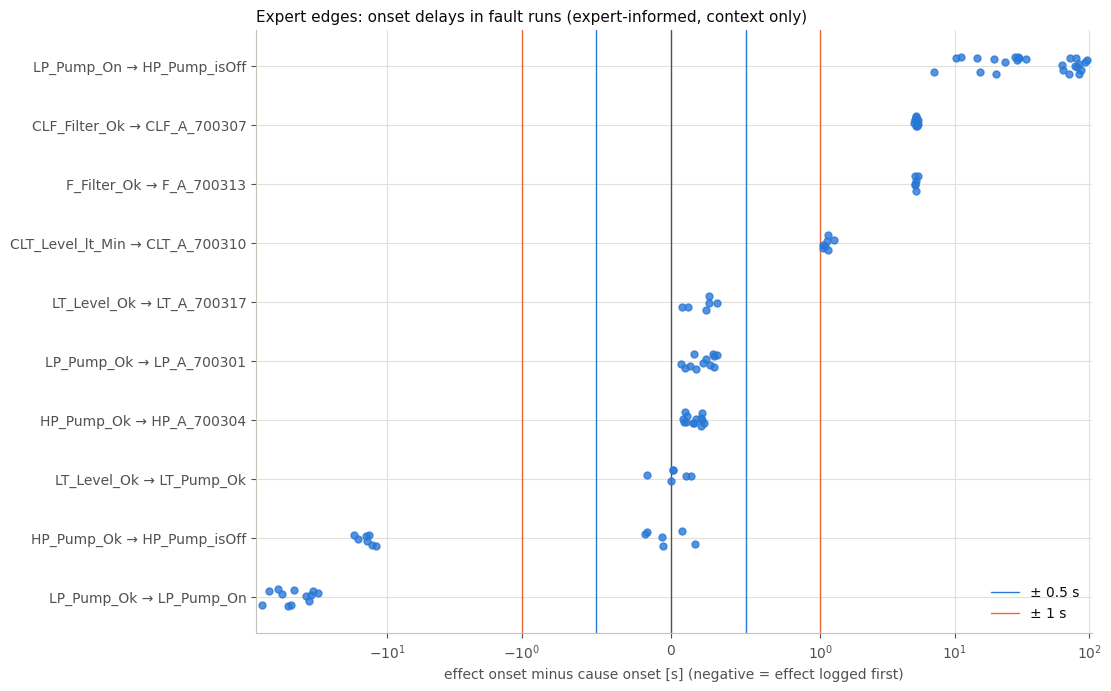

size  median    min    max  within ±0.5 s  within ±1 s
cause            effect                                                               
CLF_Filter_Ok    CLF_A_700307     12    5.19   4.94   5.30           0.00         0.00
CLT_Level_lt_Min CLT_A_700310      7    1.11   1.05   1.25           0.00         0.00
F_Filter_Ok      F_A_700313        6    5.11   5.02   5.28           0.00         0.00
HP_Pump_Ok       HP_A_700304      13    0.15   0.08   0.22           1.00         1.00
                 HP_Pump_isOff    13  -12.07 -17.60   0.16           0.46         0.46
LP_Pump_Ok       LP_A_700301      12    0.22   0.07   0.31           1.00         1.00
                 LP_Pump_On       12  -50.88 -85.79 -32.92           0.00         0.00
LP_Pump_On       HP_Pump_isOff    25   33.92   7.00  96.22           0.00         0.00
LT_Level_Ok      LT_A_700317       6    0.24   0.07   0.31           1.00         1.00
                 LT_Pump_Ok        6    0.01  -0.16   0.13           1.00         1.00

In [17]:
# figure 8 (context only): delay between onsets of expert cause and effect in fault runs
delays = data.edge_onset_delays(events, runs[runs.subsystem == SUBSYSTEM], graph)
ev.save_table(delays, f'02_{SUBSYSTEM}_expert_edge_delays')
edge_order = delays.groupby(['cause', 'effect']).delay_s.median().sort_values().index.tolist()

fig, ax = plt.subplots(figsize=(11, 0.5 * len(edge_order) + 1.8), layout='constrained')
rng = np.random.default_rng(0)
for i, (cause, effect) in enumerate(edge_order):
    d = delays.loc[(delays.cause == cause) & (delays.effect == effect), 'delay_s']
    ax.scatter(d, i + rng.uniform(-0.15, 0.15, len(d)), s=25, color=ev.COLORS[0], alpha=0.8, zorder=3)
ax.axvline(0, color=ev.INK['secondary'], linewidth=1)
for dt in INTERVALS:
    for sign in (-1, 1):
        ax.axvline(sign * dt, color=DT_COLORS[dt], linewidth=1, label=f'± {dt:g} s' if sign == 1 else None)
ax.set_xscale('symlog', linthresh=1)
ax.set_yticks(range(len(edge_order)), [f'{c} → {e}' for c, e in edge_order])
ax.set_xlabel('effect onset minus cause onset [s] (negative = effect logged first)')
ax.set_title('Expert edges: onset delays in fault runs (expert-informed, context only)')
ax.legend(loc='lower right')
ev.save_figure(fig, f'02_{SUBSYSTEM}_expert_edge_delays')
plt.show()

# per edge: runs, median delay and share of runs where both onsets fall within one interval
grouped = delays.groupby(['cause', 'effect']).delay_s
edge_summary = grouped.agg(['size', 'median', 'min', 'max'])
for dt in INTERVALS:
    edge_summary[f'within ±{dt:g} s'] = grouped.apply(lambda d: (d.abs() <= dt).mean())
edge_summary.round(2)

**What to look for.** Edges whose delays fall inside ±Δ will look *contemporaneous* (lag 0) at that interval, and lag-0 links cannot be oriented. Negative delays are effects logged before their causes, which is the batching problem from the EDA.

## F. Recording splits

- **Normal recordings:** ordered by recording number. The earliest 70% are train, the next 15% validation, the latest 15% test. Split by recording, never by time point. Stage 4 fits mechanisms on train and evaluates on held-out recordings.
- **Fault runs:** grouped by scenario into leave-one-scenario-out folds. All runs of a scenario stay in one fold. How Stage 2 uses the folds is decided in Stage 2.

In [18]:
# explicit split labels for every recording used with this subsystem
splits = data.make_splits(recordings, SUBSYSTEM)
ev.save_table(splits, f'02_{SUBSYSTEM}_splits')
splits.groupby(['split', 'fold'], dropna=False).size().rename('recordings').to_frame()

recordings
split      fold              
fault      exp_22           6
           exp_27           7
           exp_28           6
           exp_35           6
test       NaN             25
train      NaN            119
validation NaN             26

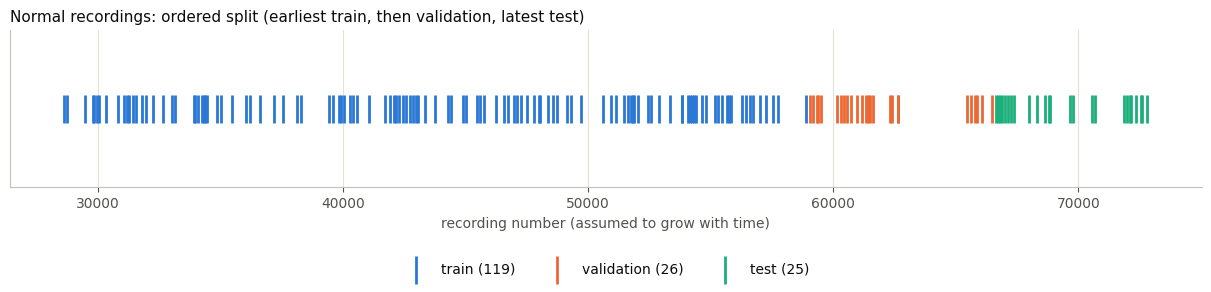

In [19]:
# figure 9: normal recordings ordered by recording number, coloured by split
normal_split = splits[splits.source == 'real_op'].copy()
normal_split['number'] = normal_split.recording_id.str.rsplit('_', n=1).str[-1].astype(int)
split_colors = {'train': ev.COLORS[0], 'validation': ev.COLORS[1], 'test': ev.COLORS[2]}

fig, ax = plt.subplots(figsize=(12, 2.8), layout='constrained')
for name, color in split_colors.items():
    part = normal_split[normal_split.split == name]
    ax.scatter(part.number, np.zeros(len(part)), marker='|', s=400, color=color, label=f'{name} ({len(part)})')
ax.set_yticks([])
ax.grid(axis='y', visible=False)
ax.set_xlabel('recording number (assumed to grow with time)')
ax.set_title('Normal recordings: ordered split (earliest train, then validation, latest test)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=3)
ev.save_figure(fig, f'02_{SUBSYSTEM}_normal_split')
plt.show()

## G. Model-ready matrices

`ModelView` turns the state table into one T×N array per recording, a T×N mask (True = unknown state) and a `data_type` vector, which is the format of tigramite's multi-dataset mode, so lags never cross recordings. Binary and Alarm variables stay 0/1. Columns that are constant in the training recordings are excluded, with the reason recorded.

We fit the view twice to show why fault runs are needed: on normal training recordings only, and on normal training recordings plus the fault runs.

In [20]:
# fit on normal training recordings only vs normal training plus fault runs
normal_train = splits.loc[splits.split == 'train', 'recording_id'].tolist()
fits = {'normal train only': normal_train, 'normal train + fault runs': normal_train + fault_ids}
views = {(dt, name): pp.ModelView.fit(states[dt], types, ids, VIEW_KIND, nodes=NODES)
         for dt in INTERVALS for name, ids in fits.items()}
pd.DataFrame([
    {'interval_s': dt, 'fitted on': name, 'kept': len(v.columns), 'excluded': len(v.exclusions),
     'excluded variables': ', '.join(e['column'] for e in v.exclusions)}
    for (dt, name), v in views.items()
])

,interval_s,fitted on,kept,excluded,excluded variables
0,0.5,normal train only,3,12,"CLF_A_700307, CLF_Filter_Ok, CLT_A_700310, CLT..."
1,0.5,normal train + fault runs,15,0,
2,1.0,normal train only,3,12,"CLF_A_700307, CLF_Filter_Ok, CLT_A_700310, CLT..."
3,1.0,normal train + fault runs,15,0,


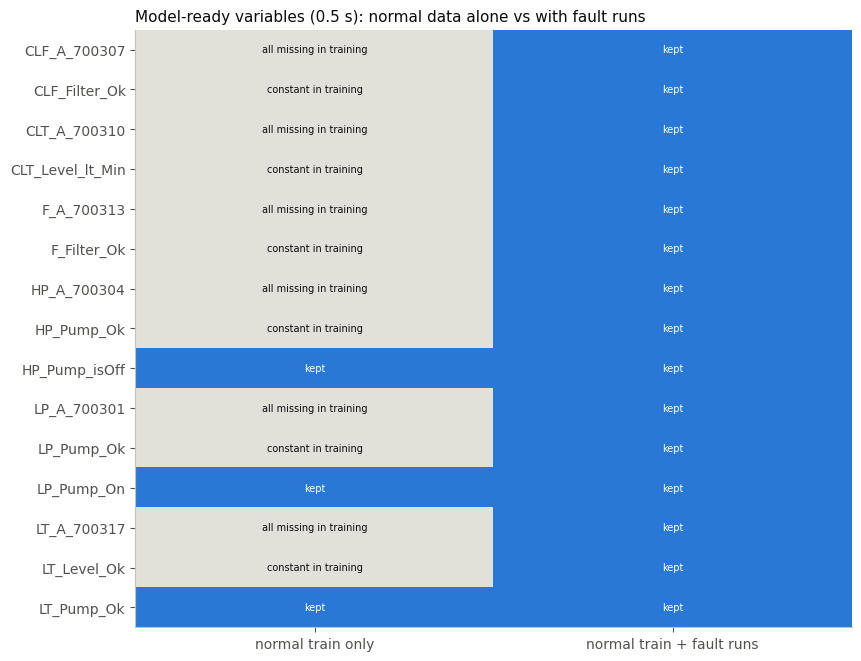

In [21]:
# figure 10: which variables each fit keeps, with the reason for exclusions
dt0 = INTERVALS[0]
names = list(fits)
reasons = {name: {e['column']: e['reason'] for e in views[(dt0, name)].exclusions} for name in names}
kept = np.array([[n not in reasons[name] for name in names] for n in NODES], dtype=float)

fig, ax = plt.subplots(figsize=(8.5, 6.5), layout='constrained')
ax.imshow(kept, cmap=ListedColormap([ev.INK['grid'], ev.COLORS[0]]), aspect='auto', vmin=0, vmax=1)
for i, n in enumerate(NODES):
    for j, name in enumerate(names):
        is_kept = n not in reasons[name]
        text = 'kept' if is_kept else reasons[name][n].replace('_', ' ')
        ax.text(j, i, text, ha='center', va='center', fontsize=7, color=ev.INK['surface'] if is_kept else ev.INK['primary'])
ax.set_xticks(range(len(names)), names)
ax.set_yticks(range(len(NODES)), NODES)
ax.grid(False)
ax.set_title(f'Model-ready variables ({dt0:g} s): normal data alone vs with fault runs')
ev.save_figure(fig, f'02_{SUBSYSTEM}_view_columns')
plt.show()

In [22]:
# final variable table: type, encoding, coverage and inclusion
variables['encoding'] = ['0/1' if types[n] in pp.BOOLEAN_TYPES else ('integer code' if types[n] == 'Categorical' else 'standardized')
                         for n in NODES]
variables['fault_runs_recording'] = fault_coverage.sum().reindex(NODES).to_numpy()
variables['normal_share_recording'] = normal_share.reindex(NODES).to_numpy()
variables['kept_normal_train_only'] = [n not in reasons['normal train only'] for n in NODES]
variables['kept_with_fault_runs'] = [n not in reasons['normal train + fault runs'] for n in NODES]
ev.save_table(variables, f'02_{SUBSYSTEM}_variables')
variables

,variable,declared_type,graph_kind,io,state_dtype,encoding,fault_runs_recording,normal_share_recording,kept_normal_train_only,kept_with_fault_runs
0,CLF_A_700307,Alarm,Alarm,None,Int8,0/1,12,0.0,False,True
1,CLF_Filter_Ok,Binary,Variable,input,Int8,0/1,12,1.0,False,True
2,CLT_A_700310,Alarm,Alarm,None,Int8,0/1,7,0.0,False,True
3,CLT_Level_lt_Min,Binary,Variable,input,Int8,0/1,7,1.0,False,True
4,F_A_700313,Alarm,Alarm,None,Int8,0/1,6,0.0,False,True
5,F_Filter_Ok,Binary,Variable,input,Int8,0/1,6,1.0,False,True
6,HP_A_700304,Alarm,Alarm,None,Int8,0/1,13,0.0,False,True
7,HP_Pump_Ok,Binary,Variable,input,Int8,0/1,13,1.0,False,True
8,HP_Pump_isOff,Binary,Variable,input,Int8,0/1,25,1.0,True,True
9,LP_A_700301,Alarm,Alarm,None,Int8,0/1,12,0.0,False,True


In [23]:
# encode all normal recordings and fault runs and save one file per interval
model_ids = normal_ids + fault_ids
view_data = {}
for dt in INTERVALS:
    view = views[(dt, 'normal train + fault runs')]
    view_data[dt] = view.transform(states[dt], model_ids)
    paths = pp.save_view_data(view, view_data[dt], data.PROCESSED_DIR, f'{SUBSYSTEM}_dt{dt:g}', interval_s=dt)
    print(f'{dt:g} s ->', ', '.join(str(p.relative_to(data.PROJECT_ROOT)) for p in paths))

0.5 s -> data/processed/coolant_dt0.5.npz, data/processed/coolant_dt0.5.json


1 s -> data/processed/coolant_dt1.npz, data/processed/coolant_dt1.json


In [24]:
# helper: one recording's model-ready matrix as an image (grey = unknown)
def plot_matrix(ax, matrices, recording_id, dt, title):
    values = matrices.arrays[recording_id].T
    mask = matrices.masks[recording_id].T
    if VIEW_KIND == 'discrete':
        cmap, vmin, vmax = ListedColormap([ev.SEQUENTIAL_BLUE[0], ev.COLORS[0]]), 0, 1
    else:
        cmap, vmin, vmax = ev.sequential_cmap(), None, None
    cmap.set_bad(ev.INK['grid'])
    n_vars = len(matrices.var_names)
    ax.imshow(np.ma.masked_array(values, mask=mask), cmap=cmap, vmin=vmin, vmax=vmax, aspect='auto',
              interpolation='nearest', extent=(0, values.shape[1] * dt, n_vars - 0.5, -0.5))
    ax.set_yticks(range(n_vars), matrices.var_names)
    ax.grid(False)
    ax.set_xlabel('time since recording start [s]')
    ax.set_title(title)

legend_handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (ev.SEQUENTIAL_BLUE[0], ev.COLORS[0], ev.INK['grid'])]
legend_labels = ['0 (False)', '1 (True)', 'unknown (masked)']

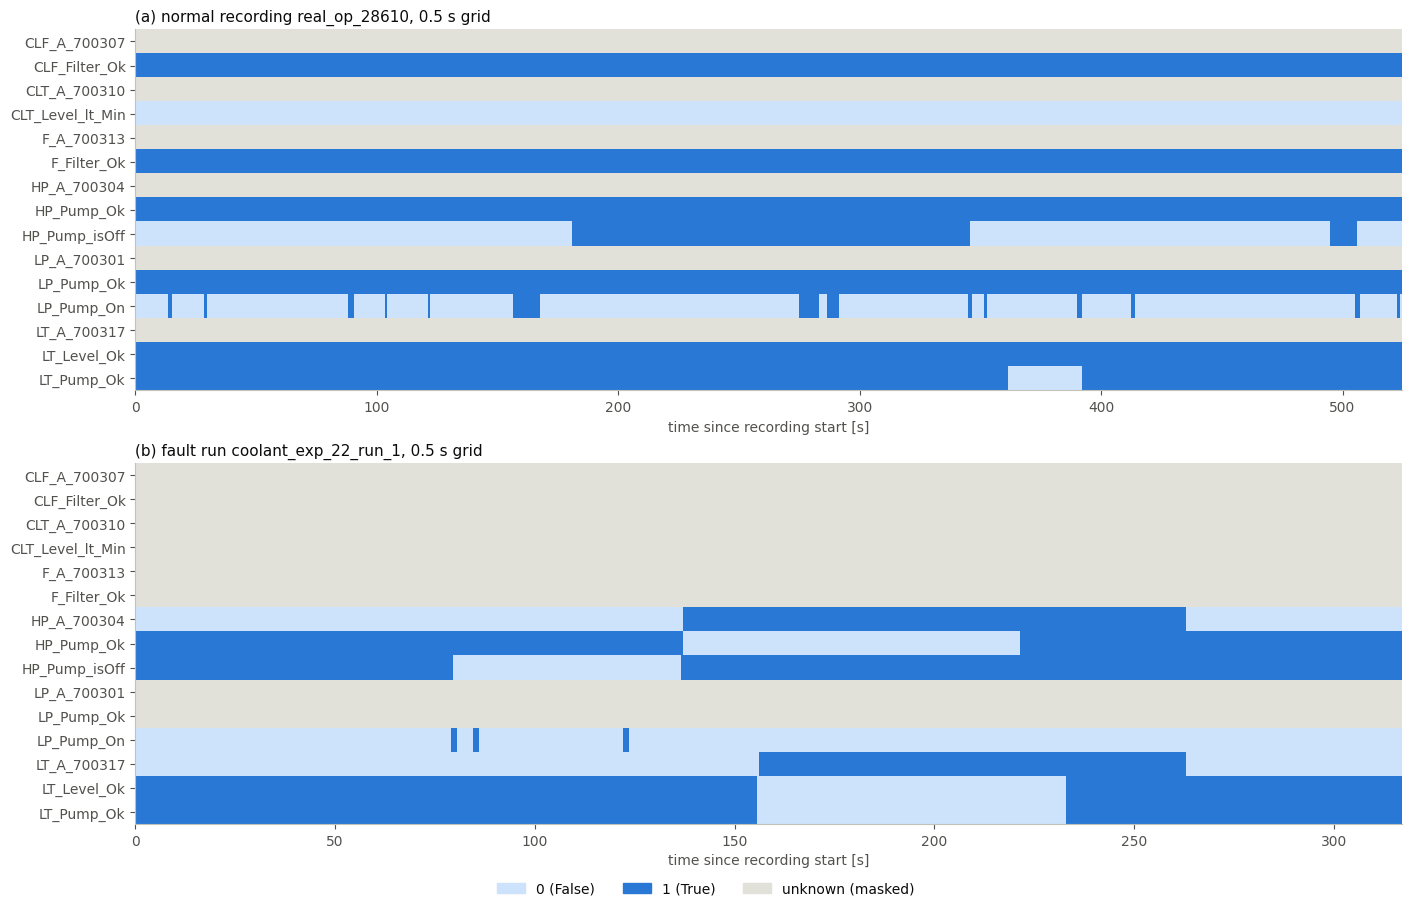

In [25]:
# figure 11: what the estimator receives: one normal recording and the example fault run (0.5 s)
normal_example = normal_train[0]
fig, (ax_a, ax_b) = plt.subplots(2, 1, figsize=(14, 9), layout='constrained')
plot_matrix(ax_a, view_data[dt0], normal_example, dt0, f'(a) normal recording {normal_example}, {dt0:g} s grid')
plot_matrix(ax_b, view_data[dt0], EXAMPLE_RUN, dt0, f'(b) fault run {EXAMPLE_RUN}, {dt0:g} s grid')
fig.legend(legend_handles, legend_labels, loc='outside lower center', ncol=3)
ev.save_figure(fig, f'02_{SUBSYSTEM}_model_ready_matrices')
plt.show()

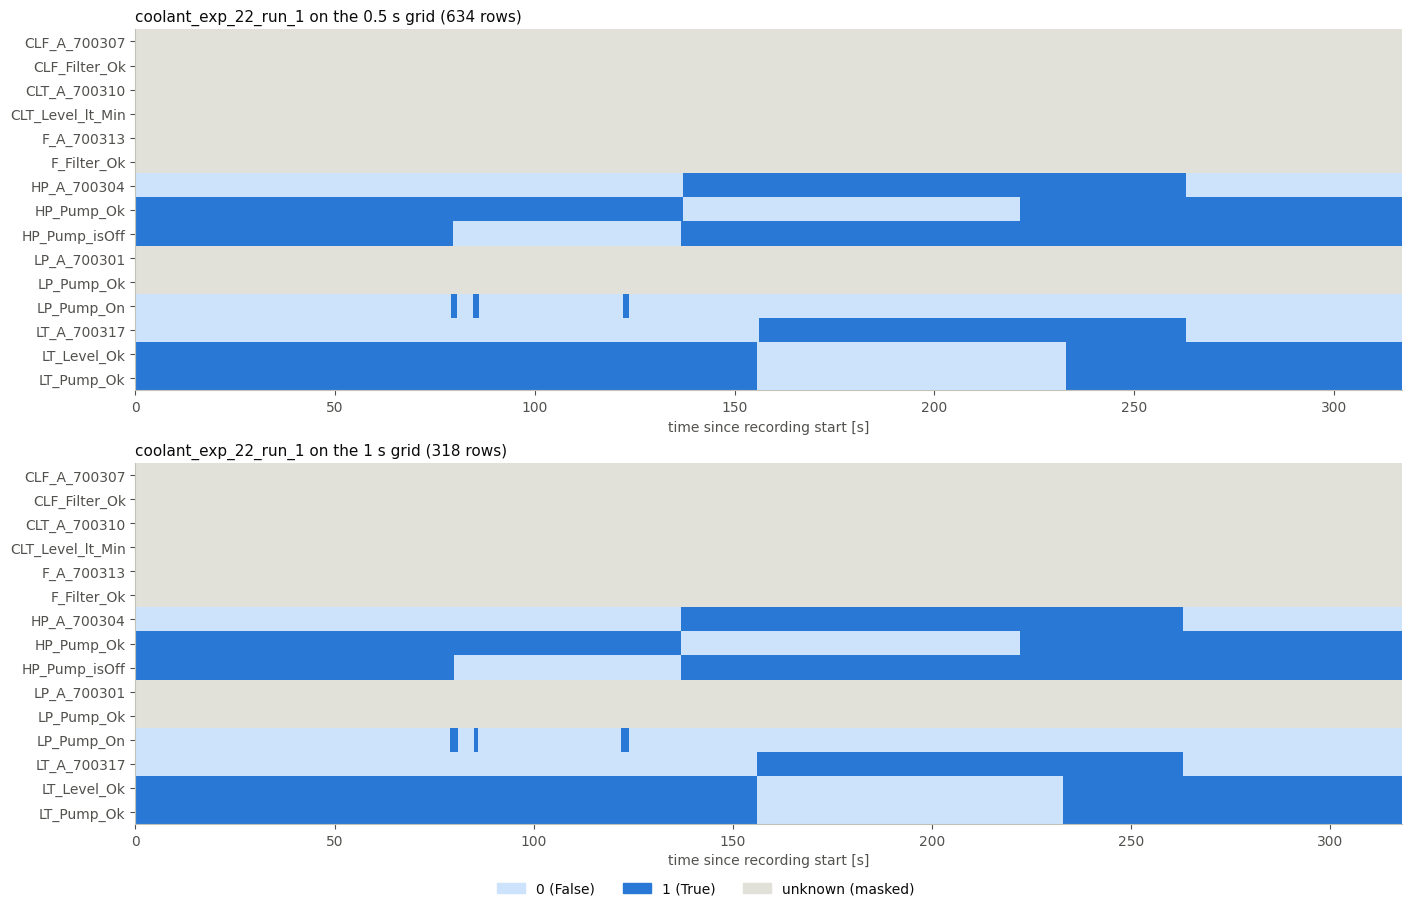

In [26]:
# figure 12: the example fault run on both grids
fig, axes = plt.subplots(len(INTERVALS), 1, figsize=(14, 4.5 * len(INTERVALS)), layout='constrained')
for ax, dt in zip(axes, INTERVALS):
    plot_matrix(ax, view_data[dt], EXAMPLE_RUN, dt, f'{EXAMPLE_RUN} on the {dt:g} s grid ({view_data[dt].arrays[EXAMPLE_RUN].shape[0]} rows)')
fig.legend(legend_handles, legend_labels, loc='outside lower center', ncol=3)
ev.save_figure(fig, f'02_{SUBSYSTEM}_model_ready_by_interval')
plt.show()

## H. Summary and choice of sampling interval

| Criterion | 0.5 s | 1 s | Source |
|---|---|---|---|
| Verification passed | yes (3.18 M cells, 0 mismatches) | yes (1.59 M cells, 0 mismatches) | section D |
| Coolant value changes kept, fault runs | 466 of 466 (100%) | 466 of 466 (100%) | figure 4 |
| Coolant value changes kept, normal operation | 3,199 of 3,199 | 3,191 of 3,199 | figure 4 |
| Grid steps hiding changes | 0 | 4 (normal, `LP_Pump_On`) | figure 5 |
| Steps with > 1 coolant variable changing, fault runs | 16% | 22% | figure 6 |
| Rows per fault run (median) | 542 | 272 | figure 7 |
| tau_max for a 10 s look-back | 20 | 10 | figure 7 |

**Findings.**
- Coolant changes slowly enough that both grids keep every change. The difference is **ordering**. At 1 s, `HP_Pump_Ok`, `HP_Pump_isOff` and `HP_A_700304` fall into one step, so they can only appear as contemporaneous (unorientable) links. At 0.5 s, `HP_Pump_isOff` lands one step *before* its expert cause: the batched publication from the EDA, now visible on the grid.
- **44 of 105** coolant variable pairs are never recorded together in any fault run. Discovery must report them as untestable (figure 3).
- With normal training data alone the view keeps only **3 of 15** variables; with fault runs it keeps all 15 (figure 10).
- **Decision:** 0.5 s is the primary grid (no loss, fewer simultaneous changes); 1 s is a sensitivity variant in notebook 03. The cost is twice the rows and twice the lags for the same look-back, which PCMCI+ handles in seconds per regime.
- *Thesis note:* the expert-edge delays (figure 8, context only) range from 0.01 s to 5 s, with some effects logged before their causes. This is why lag-0 links stay unoriented, and why only lagged links are oriented by time.

**Saved for Stage 2:** `data/processed/coolant_dt0.5.npz|json`, `coolant_dt1.npz|json`, `results/tables/02_coolant_splits.csv`, `02_coolant_co_observation.csv`.